# Tutorial 14: Training on Your Own Designs

Sooner or later every designer runs into this question: we have simulated a handful of our own designs in Ansys Q3D, so is the released capacitance model already good enough on them, or should we train on them? In this tutorial we answer it with numbers. We cross-validate the released model against a network trained on our designs alone, and then retrain the collective model with our designs added to all the public data.

**Note:** this tutorial needs the optional ML extra, `pip install "squadds[ml]"`. It builds on [Tutorial 11](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-11_Predicting_Capacitance_Matrices_from_GDS.html).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## The story

Let's say we are designing Xmon qubits: a cross in a ground pocket, a readout claw on one arm and, on some of them, a bus claw on a second arm. We changed the cross and claw dimensions a bit for our process and simulated ten of these designs in Q3D. Each one took a few minutes to an hour of solver time, depending on the mesh. Now we want to simulate a hundred more for a sweep. Before we spend that compute, we want to know whether the ML model is good enough on *our* Xmons.

There are two ways to use the ten simulations:

1. **Zero-shot:** keep the released model as it is, and use our ten designs only to measure how good it is.
2. **From scratch:** train a network on our ten designs alone (the paper's in-family recipe, about a minute per fit on a laptop).

`fit_in_family` cross-validates both and keeps the zero-shot model unless training is *clearly* better. If our family is far from anything the models have seen, a third option is to add our designs to all the public data and retrain the collective model, which we do at the end.

### Our "own" designs

For this tutorial, our ten designs are Xmons from the SQuADDS planar capacitance dataset (family `exp13`) that ship in `data/tutorial14/`. The released `QCap` model is trained on all the public data, these ten included, so its zero-shot score on them is an in-sample score and flatters it. That is fine for showing the workflow. With designs of your own that nobody has seen, the same call gives an honest comparison.

In [2]:
import os

os.environ["QISKIT_METAL_HEADLESS"] = "1"

import warnings

warnings.filterwarnings("ignore")

In [3]:
import json
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

We'll write everything into one folder, and start from a clean one.

In [4]:
work = Path("tutorial14_files")
shutil.rmtree(work, ignore_errors=True)
work.mkdir()

Each design lives in its own folder with three files: the GDS, the options that generated it (JSON) and the Q3D export, `cap_matrix.csv`.

In [5]:
data_dir = Path("data/tutorial14/xmon")
folders = sorted(data_dir.iterdir())
[f.name for f in folders]

['q3d_cap_0544',
 'q3d_cap_0554',
 'q3d_cap_0579',
 'q3d_cap_0604',
 'q3d_cap_0629',
 'q3d_cap_0654',
 'q3d_cap_0662',
 'q3d_cap_0678',
 'q3d_cap_0713',
 'q3d_cap_0757']

In [6]:
sorted(p.name for p in folders[0].iterdir())

['cap_0544.gds', 'cap_0544.json', 'cap_matrix.csv']

Here are the knobs we turned (µm), straight from the generator options:

In [7]:
params = pd.DataFrame(
    [json.loads(next(f.glob("*.json")).read_text())["generator"]["params"] for f in folders],
    index=[f.name for f in folders],
)
params.round(2)

,cross_length,cross_width,cross_gap,claw_length,claw_width,claw_gap,ground_spacing,claw_cpw_length,second_claw,second_claw_location,second_claw_length
q3d_cap_0544,303.67,22.59,28.33,82.27,19.61,8.07,10.93,26.55,True,0,121.54
q3d_cap_0554,312.47,29.59,33.68,103.74,8.12,8.93,9.17,52.76,False,270,116.35
q3d_cap_0579,236.38,35.88,33.00,55.28,13.07,4.44,11.33,39.59,False,270,168.89
q3d_cap_0604,270.26,35.79,19.82,101.17,17.56,7.15,11.64,38.10,False,270,84.33
q3d_cap_0629,302.62,38.13,26.69,119.47,9.55,7.34,10.46,43.44,True,0,58.07
q3d_cap_0654,241.03,21.84,25.21,118.57,14.78,4.96,5.38,24.96,False,0,68.10
q3d_cap_0662,216.32,21.20,25.02,90.91,16.34,6.18,4.18,28.38,True,0,162.03
q3d_cap_0678,314.28,25.47,30.83,159.86,17.98,5.85,8.49,45.37,False,270,195.43
q3d_cap_0713,228.31,25.29,34.16,169.73,12.50,7.54,8.06,34.19,False,270,111.00
q3d_cap_0757,202.74,19.94,25.39,95.18,11.63,6.20,10.65,43.05,True,0,133.53


### Look at the metal first

As in Tutorial 11, let's look at what the model sees before anything else: the ground on layer 1/0 and every conductor on layer 1/10. These GDS files also carry a small port stub on layer 2/0 at the readout claw. That is how the dataset names the nets the way Q3D did (`N` = the readout claw, `S` = the cross, `P1` = the bus claw).

In [8]:
from squadds.ml.capacitance import prepare_layout

Importing SQuADDS also loads scqubits, which switches the inline figures of the notebook to vector formats. Let's switch them back to PNG so the plots stay light.

In [9]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")

In [10]:
def plot_layout(layout, title="", ax=None):
    """Ground in grey (its etch in white), every conductor in its own color, labelled with its name."""
    ax = ax or plt.subplots(figsize=(5, 5))[1]
    for poly in getattr(layout.ground, "geoms", [layout.ground]):
        ax.fill(*poly.exterior.xy, color="0.82", lw=0)
        for hole in poly.interiors:
            ax.fill(*hole.xy, color="white", lw=0)
    for k, (name, body) in enumerate(zip(layout.names, layout.conductors)):
        for poly in getattr(body, "geoms", [body]):
            ax.fill(*poly.exterior.xy, color=plt.cm.tab10.colors[k % 10], lw=0)
        p = body.representative_point()
        ax.annotate(name, (p.x, p.y), ha="center", fontsize=9, weight="bold")
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
    ax.set_title(title)
    return ax

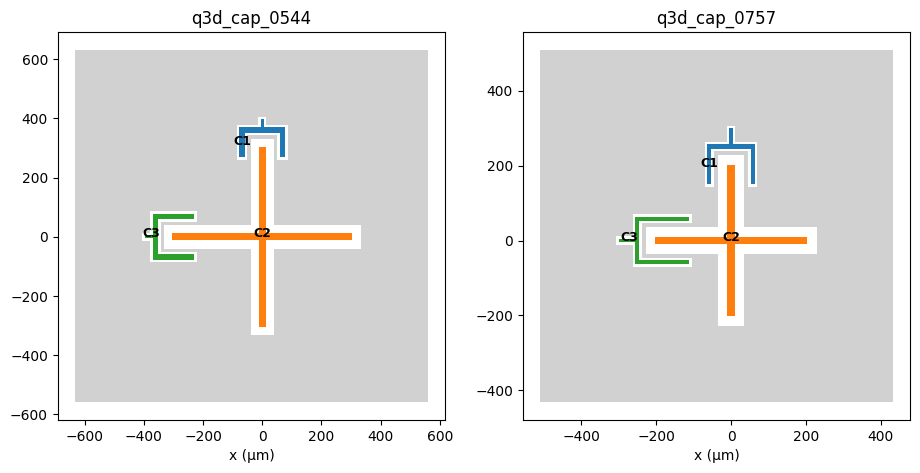

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, f in zip(axes, [folders[0], folders[-1]]):
    plot_layout(prepare_layout(next(f.glob("*.gds"))), title=f.name, ax=ax)

Two of our Xmons, both with a second (bus) claw: four conductors including ground. Six of the ten have the readout claw only (three conductors).

## Reading Q3D labels and label QC

Q3D writes one row per adaptive pass. `read_q3d_csv` keeps the last complete pass, converts it to fF and puts the ground first.

In [12]:
from squadds.ml.capacitance.training_data import Design, LabelQCError, build_shards, label_qc, read_q3d_csv

In [13]:
names, C, info = read_q3d_csv(folders[0] / "cap_matrix.csv")
info

{'passes': 40,
 'label_pass_index': 18,
 'complete_passes': 19,
 'last_pass_change_max_pct': 0.0998301175207958}

In [14]:
pd.DataFrame(C, index=names, columns=names).round(3)

,G,N,S,P1
G,337.954,-59.763,-146.468,-72.741
N,-59.763,61.904,-1.851,-0.033
S,-146.468,-1.851,152.413,-2.768
P1,-72.741,-0.033,-2.768,75.855


A single broken label quietly poisons a training set, so every label is checked before we train on it: symmetry, Maxwell signs, closure (no signal row may sum below zero) and a positive definite signal block. A label that fails is refused. QC never repairs it.

In [15]:
label_qc(C, names)

{'symmetry_rel': 0.0,
 'offdiag_max_fF': -0.032935306080153694,
 'closure_min_rel': 0.004125941015496066,
 'signal_block_min_eig_fF': 61.86542190967676,
 'passed': True}

Let's see QC do its job. Here is the same matrix with a sign typo in one mutual capacitance, the kind of thing that happens when a matrix is copied by hand:

In [16]:
broken = C.copy()
broken[1, 2] = broken[2, 1] = -broken[1, 2]
try:
    label_qc(broken, names)
except LabelQCError as err:
    print("refused:", err)

refused: positive off-diagonal entry (1.85 fF): not Maxwell signs


Great, a broken label never reaches the training set.

## Building the training shards

A `Design` pairs a GDS with its label. `build_shards` turns each one into what the networks read: the geometric embedding of the layout, the physics prior (the two thin-film solves of `optimized_physics_prior`) and the QC'd label. The label is matched to the layout's conductors **by name**, so nets are never merged. The result is a folder of shards, one file per conductor count.

In [17]:
designs = [
    Design(gds=str(next(f.glob("*.gds"))), labels=str(f / "cap_matrix.csv"), key=f"my_xmons/{f.name}", family="my_xmon")
    for f in folders
]
designs[0]

Design(gds='data/tutorial14/xmon/q3d_cap_0544/cap_0544.gds', labels='data/tutorial14/xmon/q3d_cap_0544/cap_matrix.csv', label_names=None, key='my_xmons/q3d_cap_0544', family='my_xmon', split='train', names='auto', ground_layers=((1, 0),), conductor_layers=((1, 10),), meta={})

In [18]:
built = build_shards(designs, work / "shards", threads=2)
{k: built[k] for k in ("layouts", "refused", "seconds")}

{'layouts': 10, 'refused': [], 'seconds': 16.825554789975286}

In [19]:
from squadds.ml.capacitance.training_data import shard_summary

shard_summary(work / "shards")

{'layouts': 10,
 'by_split': {'train': 10},
 'by_family': {'train/my_xmon': 10},
 'n_range': [3, 4],
 'prior_version': 'v2m_sf_fc_dipfill_margin_slabfar'}

<details>
<summary><b>Priors computed on your own machine</b></summary>

The priors are computed on *your* machine. On macOS they differ from the released priors (computed on x86 Linux) by up to about $2.4 \times 10^{-3}$ relative on some layouts. That is harmless for your own models. It is the reason the maintainers compute every released prior on the same x86 machines.

</details>

## Zero-shot or from scratch? `fit_in_family`

`fit_in_family` runs a $k$-fold cross-validation over our ten designs. In each fold, two designs are held out and predicted twice:

- by the **zero-shot** model (`base`), which never changes, and
- by a network trained **from scratch** on the other eight designs.

Both candidates are scored on exactly the same held-out layouts, so we can compare them design by design. The from-scratch recipe wins only if it is *materially* better. Otherwise the zero-shot model is kept, and it wins ties.

<details>
<summary><b>What "materially better" means</b></summary>

The layout-bootstrap 95 % interval of the difference must exclude zero **and** the gain must exceed 0.25 percentage points of median error or 0.05 fF of MAE (the equivalence margin of the paper).

</details>

The recipe is the paper's, written out in `TrainConfig` (these are the defaults of the released models):

In [20]:
from squadds.ml.capacitance.train import TrainConfig, fit_in_family

TrainConfig()

TrainConfig(steps=18000, lr=0.001, weight_decay=0.0001, lr_min=1e-05, grad_clip=5.0, huber_delta=0.05, w_signal_self=0.1, w_ground_self=0.02, max_batch=64, pair_budget=8192, width=64, standardise_clip=10.0, log_every=500)

Each fit is the full recipe, 18,000 steps. We run the five folds in four processes with 2 CPU threads each.

In [21]:
cv = fit_in_family(work / "shards", work / "in_family", k_folds=5, base="QCap", threads=2, processes=4,
                   family="my_xmon")
print(cv)

in-family CV (10 designs): chosen = zero-shot; from-scratch only if materially better (95% interval excludes zero and the gain exceeds the margin); zero-shot wins ties


`cv.report` holds the layout-mean scores of both candidates, per kind of matrix entry: all mutual capacitances, the signal-signal and signal-ground mutuals, and the self capacitances.

In [22]:
cv.report[["candidate", "kind", "layouts", "median_pct", "mae_fF", "rmse_fF"]].round(4)

,candidate,kind,layouts,median_pct,mae_fF,rmse_fF
0,zero-shot,ground_self,10,0.2572,0.7379,0.7379
1,zero-shot,mutual,10,0.2683,0.1199,0.1732
2,zero-shot,signal-ground,10,0.2269,0.1949,0.2250
3,zero-shot,signal-signal,10,0.4005,0.0094,0.0101
4,zero-shot,signal_self,10,0.3135,0.2831,0.2994
5,from-scratch,ground_self,10,1.2728,3.6142,3.6142
6,from-scratch,mutual,10,0.4696,0.2601,0.3750
7,from-scratch,signal-ground,10,0.4689,0.4140,0.4812
8,from-scratch,signal-signal,10,0.6769,0.0173,0.0194
9,from-scratch,signal_self,10,0.4490,0.4091,0.4710


The paired difference (from scratch minus zero-shot) with its 95 % interval, and the decision:

In [23]:
diff = cv.decision["paired_from_scratch_minus_zero_shot"]
pd.DataFrame({k: v for k, v in diff.items() if k != "layouts"}).T.round(4)

,diff,lo,hi
median_pct,0.2013,0.0994,0.3088
mae_fF,0.1402,0.0772,0.2068
rmse_fF,0.2017,0.1064,0.3002


In [24]:
cv.decision["chosen"], cv.decision["base"]

('zero-shot', 'QCap')

In [25]:
pd.Series({k: v for k, v in cv.timing.items() if k != "per_fit_s"})

build_s                                  0.00266
cv_fits_s                              77.099217
final_s                                 0.000007
total_s                                77.278973
threads                                        2
processes                                      4
device                                       cpu
machine      Apple M5 Pro, 18 CPUs, Darwin arm64
dtype: object

Let's look at it design by design:

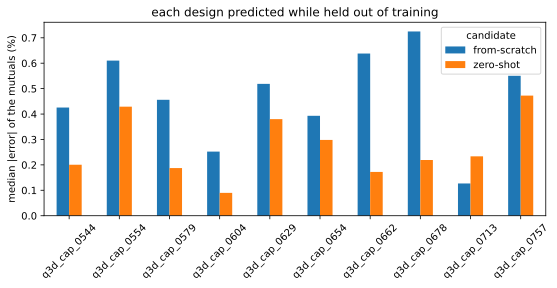

In [26]:
per_layout = pd.read_csv(work / "in_family" / "cv_layouts.csv").query("kind == 'mutual'")
wide = per_layout.pivot(index="key", columns="candidate", values="median_pct")
wide.index = [k.split("/")[-1] for k in wide.index]
ax = wide.plot.bar(figsize=(9, 3.5), rot=45)
ax.set_ylabel("median |error| of the mutuals (%)")
ax.set_title("each design predicted while held out of training");

On our ten Xmons, the zero-shot QCap beats the network trained from scratch on every kind of entry, 0.27 % on the mutual capacitances (MAE 0.120 fF, RMSE 0.173 fF) against 0.47 % (MAE 0.260 fF, RMSE 0.375 fF), and the 95 % interval of the difference excludes zero, so `fit_in_family` keeps the zero-shot model. Keep in mind that QCap was trained on these ten designs, so its side of the comparison is an in-sample score. Eight designs are simply too few to learn what 45,771 layouts taught the released networks. The gap is largest on the self capacitance of the ground. The five fits took 77 s of wall time (four processes with 2 threads each on an Apple M5 Pro).

So for our Xmons the answer is: don't train. Run the sweep with the model and keep a few Q3D spot checks. Ten designs is a small sample, though, and from-scratch training improves quickly with more designs, so it is worth repeating this check as your set grows.

## Retraining the collective model

Sometimes your family is far from anything in the public data: the zero-shot error is too large, and ten designs are too few to train on alone. Then the best option is usually to add your designs to **all** the public data and retrain the collective model with the QCap recipe. `retrain_collective` does exactly that:

1. it merges your shards with the all-data training set (refusing a different feature schema or prior version, and duplicate keys),
2. it trains **3 seeds**: three networks from different random initialisations, whose mean is the prediction. One network carries some seed-to-seed noise, and the ensemble of three averages most of it out. That is why every released model is a 3-seed ensemble.

<details>
<summary><b>Your retrain will not be bit-identical to the released models</b></summary>

The released models are trained by the maintainers on x86 Linux CPUs, 2 threads per seed. Training is chaotic, so another CPU, thread count or library version changes the training trajectory. A retrain on a GPU, on a Mac, or with other library versions gives a slightly different set of networks, whose predictions move by a few tenths of a percent, about as much as between two seeds. It is recorded as such in every checkpoint. That is fine for your own designs, but it is never mixed into the released data.

</details>

The all-data training set is the dataset's `model_input` table. Here we point to a local copy of the QCap shards through the environment variable `SQUADDS_CAPML_BASE_SHARDS`.

In [27]:
base_shards = Path(os.environ.get("SQUADDS_CAPML_BASE_SHARDS", "qcap_shards"))
base_summary = shard_summary(base_shards)
{k: base_summary[k] for k in ("layouts", "by_split", "n_range", "prior_version")}

{'layouts': 45771,
 'by_split': {'train': 45771},
 'n_range': [2, 68],
 'prior_version': 'v2m_sf_fc_dipfill_margin_slabfar'}

Our stand-in Xmons are public designs, so QCap's training set already contains them (as `exp13/<design>`). To avoid counting them twice, let's drop them from the base first. With designs of your own you skip this step.

In [28]:
from squadds.ml.capacitance.training_data import subset_shards

In [29]:
ours = [f"exp13/{f.name}" for f in folders]
base_clean = subset_shards(base_shards, work / "base_without_ours",
                           keep=lambda d: ~np.isin(d["key"].astype(str), ours))
print(base_summary["layouts"] - shard_summary(base_clean)["layouts"], "of our designs removed from the base")

10 of our designs removed from the base


Now the retrain itself: three seeds of the full recipe on about 45,800 layouts, in three processes with 2 threads each. On my laptop this takes a while but on a cluster node it is a few minutes per seed.

In [30]:
from squadds.ml.capacitance.train import retrain_collective

In [31]:
collective, runs = retrain_collective(work / "shards", base_clean, work / "collective", seeds=(0, 1, 2),
                                     processes=3, threads=2)

In [32]:
pd.DataFrame(runs)[["seed", "steps", "train_seconds", "threads", "device", "machine"]]

,seed,steps,train_seconds,threads,device,machine
0,0,18000,273.033274,2,cpu,"Intel(R) Xeon(R) Gold 6130 CPU @ 2.10GHz, 32 C..."
1,1,18000,273.280381,2,cpu,"Intel(R) Xeon(R) Gold 6130 CPU @ 2.10GHz, 32 C..."
2,2,18000,273.497825,2,cpu,"Intel(R) Xeon(R) Gold 6130 CPU @ 2.10GHz, 32 C..."


`collective` is a model like any other, so it goes straight into a `CapacitancePredictor`. We retrained on (almost) the same data with the same recipe as QCap, so the two should agree closely on one of our Xmons. This is a reproducibility check, not an accuracy score, since both models trained on this design.

In [33]:
from squadds.ml.capacitance import CapacitancePredictor, load_model

In [34]:
gds = designs[-1].gds
qcap = CapacitancePredictor(load_model("QCap"), threads=2).predict(gds)
retrained = CapacitancePredictor(collective, threads=2).predict(gds)

In [35]:
def mutuals(C, names):
    """The mutual capacitances (fF, positive) of a Maxwell matrix, one entry per pair of conductors."""
    C = np.asarray(C)
    return pd.Series({f"{names[i]} to {names[j]}": -C[i, j] for i in range(len(names)) for j in range(i + 1, len(names))})

In [36]:
check = pd.DataFrame({"QCap (fF)": mutuals(qcap.matrix_fF, qcap.names),
                      "retrained (fF)": mutuals(retrained.matrix_fF, retrained.names)})
check["difference (%)"] = 100 * (check["retrained (fF)"] / check["QCap (fF)"] - 1)
check.round(4)

,QCap (fF),retrained (fF),difference (%)
G to C1,57.9446,57.6799,-0.4569
G to C2,94.7620,94.8065,0.0470
G to C3,69.8809,69.5818,-0.4281
C1 to C2,1.7303,1.7390,0.4992
C1 to C3,0.0543,0.0550,1.2871
C2 to C3,2.5497,2.5563,0.2570


The conductors are named in file order here: `C1` is the readout claw, `C2` the cross and `C3` the bus claw. The retrained ensemble agrees with QCap to about the size of the seed-to-seed spread, with the largest relative difference on the tiny coupling between the two claws. Our three seeds were trained on a different CPU and with different library versions than the released ones, so their training trajectories differ. Both models trained on this design, so neither column is an accuracy score.

## Retraining on your own cluster

On a cluster, the natural unit of work is one seed per task. `squadds-ml train --slurm` writes a generic SLURM array script (one array task per seed) with no site-specific accounts, partitions or modules: pass your own with `--partition` and `--account`, or leave them out and let your cluster's defaults apply.

In [37]:
!squadds-ml train --data tutorial14_files/shards --out tutorial14_files/runs --seeds 0,1,2 --threads 2 --time 01:00:00 --slurm tutorial14_files/train_array.sh

wrote tutorial14_files/train_array.sh: sbatch tutorial14_files/train_array.sh


Here is the script it wrote (we shorten our working directory to `.` for readability):

In [38]:
script = (work / "train_array.sh").read_text()
print(script.replace(str(Path.cwd().resolve()), ".").replace(sys.executable, "python"))

#!/bin/bash
#SBATCH --job-name=squadds-ml-train
#SBATCH --array=0-2
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=2
#SBATCH --mem=6G
#SBATCH --time=01:00:00
#SBATCH --output=./tutorial14_files/runs/logs/%x_%A_%a.out
set -euo pipefail
export OMP_NUM_THREADS=2 MKL_NUM_THREADS=2 OPENBLAS_NUM_THREADS=2
SEEDS=(0 1 2)
SEED=${SEEDS[$SLURM_ARRAY_TASK_ID]}
mkdir -p ./tutorial14_files/runs
python -m squadds.ml.capacitance.train --data ./tutorial14_files/shards --out ./tutorial14_files/runs --arm full_gnn --seeds "$SEED" --steps 18000 --threads 2 --device cpu



Submit it with `sbatch train_array.sh`. When the three tasks are done, `trained_model` turns the run folders into a model for `CapacitancePredictor`:

```python
from squadds.ml.capacitance.train import trained_model

model = trained_model(["tutorial14_files/runs/s0", "tutorial14_files/runs/s1", "tutorial14_files/runs/s2"])
CapacitancePredictor(model).predict("my_next_xmon.gds")
```

The same works from Python with `squadds.ml.capacitance.slurm.write_slurm_array` (for example with `gpus=1` and `device="cuda"`). GPU fits are not bit-identical to the CPU ones either..

## Next Steps...

In the next [tutorial](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-15_Contributing_Capacitance_Data_and_Models.html), we will learn how to contribute your simulations and your models back to SQuADDS, so that the next designer starts from a better model.

## License

<div style='width: 100%; background-color:#3cb1c2;color:#324344;padding-left: 10px; padding-bottom: 10px; padding-right: 10px; padding-top: 5px'>
    <h3>This code is a part of SQuADDS</h3>
    <p>Developed by Sadman Ahmed Shanto</p>
    <p>This tutorial is written by Sadman Ahmed Shanto and Claude Opus 5.5</p>
    <p>&copy; Copyright Sadman Ahmed Shanto & Eli Levenson-Falk 2026.</p>
    <p>This code is licensed under the MIT License. You may<br> obtain a copy of this license in the LICENSE.txt file in the root directory<br> of this source tree.</p>
    <p>Any modifications or derivative works of this code must retain this<br>copyright notice, and modified files need to carry a notice indicating<br>that they have been altered from the originals.</p>
</div>